# code_228 · Capstone: causal sensor histories, native forecasting and grouped uncertainty

**Book:** section 43.3. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials and explicitly acquired cached checkpoints. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_43_GUIDE.md), [execution evidence](../CHAPTER_43_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_228).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Complete projects retain framing, data provenance, baseline comparisons, fitting/selection/calibration boundaries, independent assessment, measured resources and decision authority. Variable resource observations are stored separately from deterministic scientific RESULTS. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or new asset is added; existing pinned checkpoints are reused. See [asset acquisition and licence](../CHAPTER_43_ASSETS.md).


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8028;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
Darwin arm64 CPU; seed 8028


## Define sensor provenance, historical windows and available outcomes
 Generate 32 independent buildings with three connected sensors and 280 hourly values each. A shared daily cycle plus spatially coupled autoregressive residuals creates dependence within a building. Predict horizons 1,6,12 from a historical 128-value context; lag models use the last 24 own values and, where declared,24 neighbour-mean values. Source buildings 0–11 use origins 128/144/160; development 12–15 uses 180; calibration 16–25 uses 192/204/216; final 26–31 uses 228/240/252. An origin o admits values through o−1, while horizon h targets index o+h−1 and becomes available one hour later. All fitting, development and calibration outcomes mature before the next role's first prediction. Alter an entire final future suffix and require that origin's own/neighbor features and native context remain unchanged. No future covariate or final outcome enters feature construction.


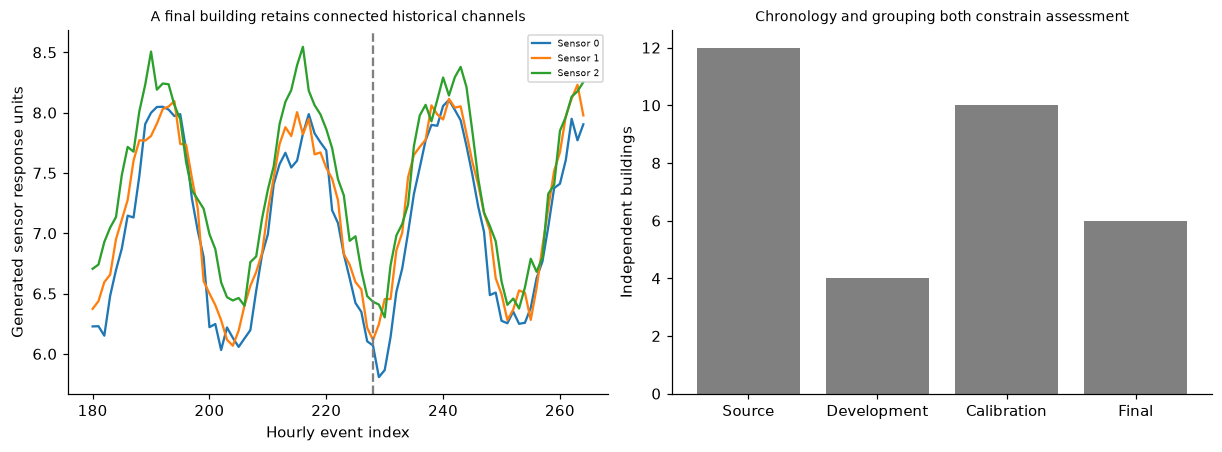

In [2]:
import hashlib,os,importlib.metadata
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
adjacency=np.array([[0.,1,0],[.5,0,.5],[0,1,0]]);values=np.empty((32,3,280))
for b in range(32):
    phase=rng.uniform(0,2*np.pi);amplitude=rng.uniform(.7,1.4);offset=rng.normal(scale=.5);residual=np.zeros((3,280))
    for t in range(1,280):residual[:,t]=.55*residual[:,t-1]+.2*adjacency@residual[:,t-1]+rng.normal(scale=.12,size=3)
    values[b]=7+offset+amplitude*np.sin(2*np.pi*np.arange(280)/24+phase)[None]+np.arange(3)[:,None]*.15+residual
horizons=np.array([1,6,12])
def window(array,b,c,origin):
    context=array[b,c,origin-128:origin].copy();neighbour=(adjacency@array[b,:,origin-24:origin])[c];return np.r_[context[-24:],neighbour],context
def requests(buildings,origins):
    rows=[];features=[];contexts=[];targets=[]
    for b in buildings:
        for origin in origins:
            for c in range(3):
                feature,context=window(values,b,c,origin);rows.append((b,c,origin));features.append(feature);contexts.append(context);targets.append(values[b,c,origin+horizons-1])
    return np.array(rows),np.array(features),np.array(contexts),np.array(targets)
train=requests(range(12),[128,144,160]);dev=requests(range(12,16),[180]);cal=requests(range(16,26),[192,204,216]);final=requests(range(26,32),[228,240,252]);altered=values.copy();altered[26,:,228:]+=999;original=window(values,26,0,228);intervened=window(altered,26,0,228);assert all(np.array_equal(a,b) for a,b in zip(original,intervened));assert train[0][:,2].max()+12<=dev[0][:,2].min();assert dev[0][:,2].max()+12<=cal[0][:,2].min();assert cal[0][:,2].max()+12<=final[0][:,2].min();assert not set(train[0][:,0])&set(final[0][:,0]);RESULTS.update(building_roles=[12,4,10,6],sensors_per_building=3,horizons_hours=horizons.tolist(),source_forecast_windows=len(train[0]),development_forecast_windows=len(dev[0]),calibration_forecast_windows=len(cal[0]),final_forecast_windows=len(final[0]),native_context_hours=128,lag_context_hours=24,future_feature_intervention_difference=0.,source_dev_cal_final_outcomes_mature_before_next_role=True);fig,axes=plt.subplots(1,2,figsize=(11,4))
for c in range(3):axes[0].plot(range(180,265),values[26,c,180:265],label=f'Sensor {c}')
axes[0].axvline(228,color='.5',linestyle='--');axes[0].set(xlabel='Hourly event index',ylabel='Generated sensor response units',title='A final building retains connected historical channels');axes[0].legend(fontsize=6);axes[1].bar(['Source','Development','Calibration','Final'],[12,4,10,6],color='.5');axes[1].set(ylabel='Independent buildings',title='Chronology and grouping both constrain assessment');plt.show()


## Compare five actual forecasting families without future-based imputation
 Seasonal prediction copies the same daily phase from the last observed day. A classical ridge autoregression uses 24 own lags; histogram boosting and a48–32–3 neural network use own and neighbour lags. Fix boosted iterations 60/seven leaves, ridge alpha 1 and neural 250 Adam steps; a boosted own-lag ablation checks spatial contribution. Native Chronos-BoltTiny uses its exact cached pretrained files from the [asset guide](../CHAPTER_43_ASSETS.md), verifies every hash, loads locally with float32 CPU inference and takes its native median at the three horizons. No checkpoint fine-tuning occurs. Development mean squared error chooses the family; no final error sets hyperparameters or chooses a model. Fitting histories, context sizes and upstream pretraining compute differ, so this is a declared task comparison rather than equal-total-compute benchmarking.


W1022 15:20:11.469000 72393 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


,Seasonal,AR ridge,Boosted spatial,Neural spatial,Frozen Bolt
1,0.155924,0.106312,0.176045,0.127048,0.104020
6,0.183298,0.199029,0.252580,0.190020,0.168386
12,0.202836,0.171210,0.228224,0.169766,0.160630


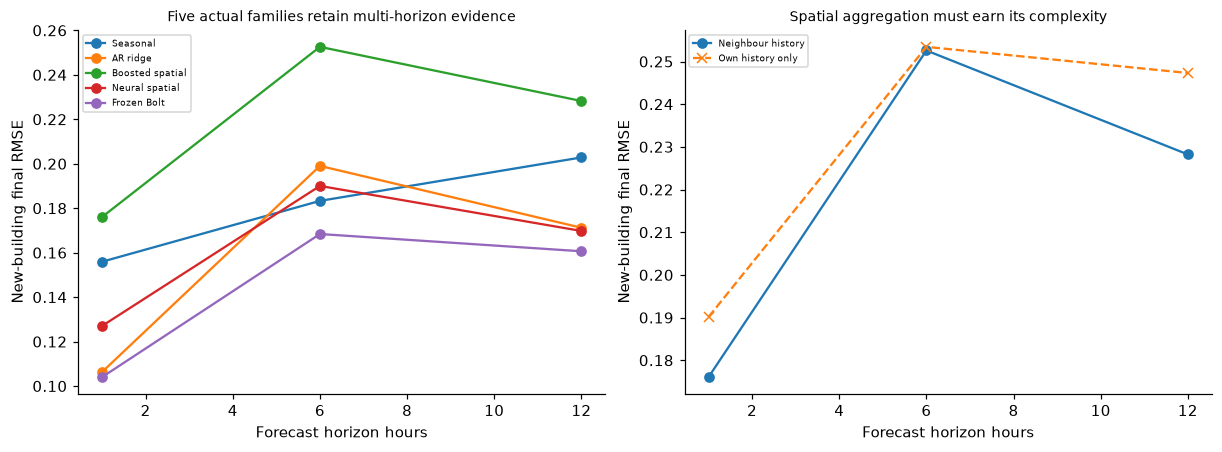

In [3]:
x,y=train[1],train[3];scaler=StandardScaler().fit(x);classical=Ridge(alpha=1).fit(x[:,:24],y);boost=MultiOutputRegressor(HistGradientBoostingRegressor(max_iter=60,max_leaf_nodes=7,early_stopping=False,random_state=SEED)).fit(x,y);ablation=MultiOutputRegressor(HistGradientBoostingRegressor(max_iter=60,max_leaf_nodes=7,early_stopping=False,random_state=SEED)).fit(x[:,:24],y);centre=y.mean(0);spread=y.std(0);net=nn.Sequential(nn.Linear(48,32),nn.Tanh(),nn.Linear(32,3));optimizer=torch.optim.Adam(net.parameters(),lr=.015,weight_decay=.005);tx=torch.tensor(scaler.transform(x));ty=torch.tensor((y-centre)/spread)
for _ in range(250):
    optimizer.zero_grad();loss=(net(tx)-ty).square().mean();loss.backward();optimizer.step()
net.eval()
def neural(features,contexts):
    with torch.no_grad():return net(torch.tensor(scaler.transform(features))).numpy()*spread+centre
os.environ['HF_HUB_OFFLINE']='1';os.environ['HF_HUB_DISABLE_PROGRESS_BARS']='1'
from chronos import BaseChronosPipeline
from transformers.utils import logging as transformer_logging
transformer_logging.disable_progress_bar();ROOT=next(p for p in [Path.cwd(),Path.cwd().parent,Path.cwd()/'examples'] if (p/'examples.json').is_file());folder=ROOT/'build/model-cache/models--amazon--chronos-bolt-tiny/snapshots/a0e552de83495b5c28c14c71c374f3e33280b340';files=[('README.md',8659,'cc7f60bc7290b5e6146589dae9842a3c9b59d254e9d1d65fc2ef127f3c2498cd'),('config.json',1120,'278f0086733031635fb1c861cb01c1bad6477420c7fcb19381a2993e335785e0'),('model.safetensors',34622352,'75068728d376d2bec670379eeef4bfb4d24c0cfe24d957451f8d19b447030a32')]
for name,length,digest in files:
    path=folder/name;assert path.is_file(),'Explicitly acquire Chapter43 models; see CHAPTER_43_ASSETS.md';blob=path.read_bytes();assert len(blob)==length and hashlib.sha256(blob).hexdigest()==digest
del blob
for package in ['chronos-forecasting','transformers','accelerate']:VERSIONS[package]=importlib.metadata.version(package)
bolt=BaseChronosPipeline.from_pretrained(str(folder),device_map='cpu',dtype=torch.float32,local_files_only=True);weight_hash=lambda:hashlib.sha256(b''.join(p.detach().cpu().numpy().tobytes() for p in bolt.model.parameters())).hexdigest();frozen=weight_hash()
def native(features,contexts):
    with torch.no_grad():return bolt.predict(torch.tensor(contexts,dtype=torch.float32),prediction_length=12).numpy()[:,4,horizons-1]
predictors={'Seasonal':lambda f,c:c[:,-24+horizons-1],'AR ridge':lambda f,c:classical.predict(f[:,:24]),'Boosted spatial':lambda f,c:boost.predict(f),'Neural spatial':neural,'Frozen Bolt':native};dev_scores={name:float(np.mean((fn(dev[1],dev[2])-dev[3])**2)) for name,fn in predictors.items()};chosen=min(dev_scores,key=dev_scores.get);predictions={name:fn(final[1],final[2]) for name,fn in predictors.items()};final_scores={name:np.sqrt(np.mean((pred-final[3])**2,axis=0)).tolist() for name,pred in predictions.items()};assert weight_hash()==frozen;assert all(pred.shape==(54,3) and np.all(np.isfinite(pred)) for pred in predictions.values());RESULTS.update(development_MSE=dev_scores,development_selected_family=chosen,final_RMSE_by_horizon=final_scores,final_boosted_without_spatial_RMSE_by_horizon=np.sqrt(np.mean((ablation.predict(final[1][:,:24])-final[3])**2,axis=0)).tolist(),frozen_pretrained_weights_unchanged=True,native_quantile_median_index=4,neural_source_steps=250);display(pd.DataFrame(final_scores,index=horizons));fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,error in final_scores.items():axes[0].plot(horizons,error,'o-',label=name)
axes[0].set(xlabel='Forecast horizon hours',ylabel='New-building final RMSE',title='Five actual families retain multi-horizon evidence');axes[0].legend(fontsize=6);axes[1].plot(horizons,final_scores['Boosted spatial'],'o-',label='Neighbour history');axes[1].plot(horizons,RESULTS['final_boosted_without_spatial_RMSE_by_horizon'],'x--',label='Own history only');axes[1].set(xlabel='Forecast horizon hours',ylabel='New-building final RMSE',title='Spatial aggregation must earn its complexity');axes[1].legend(fontsize=6);plt.show()


## Calibrate whole-building bands and stress a declared monitoring interface
 For the development-selected family, take the maximum absolute calibration residual across each building's three sensors, three origins and three horizons. Ten independent calibration buildings give rank ceil((10+1)*0.9)=10, so use the largest score as a common half-width. Report final whole-building simultaneous coverage and marginal coverage separately. Temporal origins, phase and population assumptions still matter; no unconditional temporal/OOD coverage guarantee is claimed. Stress missing channels with causal forward fill of the admitted history only, delayed history by three hours while retaining the actual prediction deadline, and an amplitude change after the forecast origin. All missingness masks are generated independently of the final outcomes. A monitoring fixture records availability, forecast horizon, model version and delayed outcome maturity; it never calls a live service. Resource measurements remain separate run observations.


,model,windows,horizons,repetitions,median_seconds
0,Seasonal,54,3,3,0.000002
1,AR ridge,54,3,3,0.000030
2,Boosted spatial,54,3,3,0.000561
3,Neural spatial,54,3,3,0.000067
4,Frozen Bolt,54,3,3,0.006807


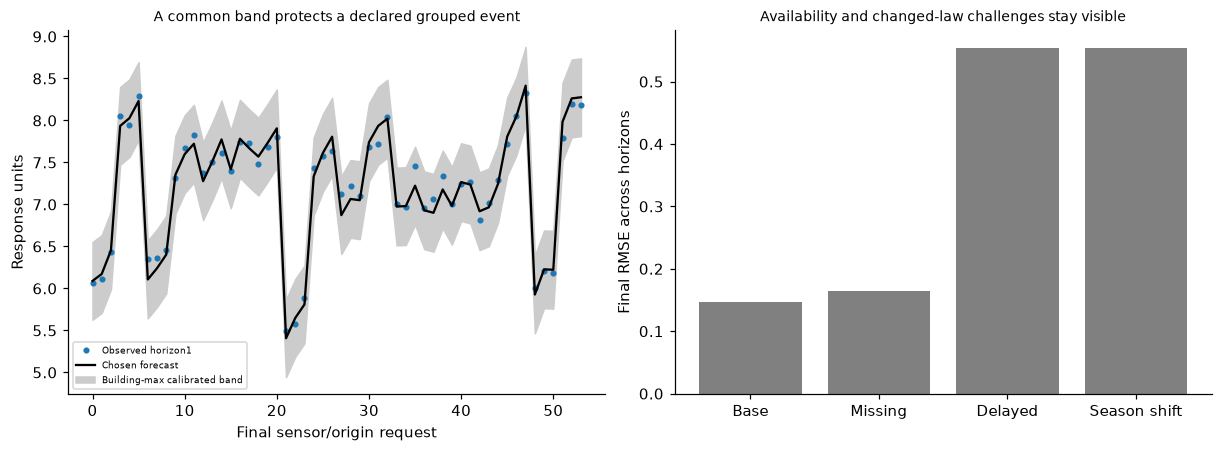

In [4]:
selected=predictors[chosen];cp=selected(cal[1],cal[2]);scores=np.array([np.max(abs(cp[cal[0][:,0]==b]-cal[3][cal[0][:,0]==b])) for b in range(16,26)]);rank=int(np.ceil(11*.9));half=float(np.sort(scores)[rank-1]);p=predictions[chosen];inside=abs(p-final[3])<=half;whole=[bool(np.all(inside[final[0][:,0]==b])) for b in range(26,32)];assert rank==10 and len(scores)==10 and len(whole)==6
def fill_past(context):
    out=context.copy();seen=np.flatnonzero(np.isfinite(out));assert len(seen)>0;out[:seen[0]]=out[seen[0]]
    for j in range(seen[0]+1,len(out)):
        if not np.isfinite(out[j]):out[j]=out[j-1]
    return out
missing_values=values.copy();mask=rng.random(missing_values.shape)<.15;missing_values[mask]=np.nan;stress_features=[];stress_contexts=[];delayed_features=[];delayed_contexts=[]
for b,c,origin in final[0]:
    filled=np.array([fill_past(missing_values[b,j,origin-128:origin]) for j in range(3)]);context=filled[c];neighbour=(adjacency@filled[:,-24:])[c];stress_contexts.append(context);stress_features.append(np.r_[context[-24:],neighbour]);f,ctx=window(values,b,c,origin-3);delayed_features.append(f);delayed_contexts.append(ctx)
missing_prediction=selected(np.array(stress_features),np.array(stress_contexts));delayed_prediction=selected(np.array(delayed_features),np.array(delayed_contexts));shift_target=final[3].copy()
for j,(b,c,origin) in enumerate(final[0]):shift_target[j]+=.9*np.sin(2*np.pi*(origin+horizons-1)/24)
stress={'missing_past_15pct_RMSE':float(np.sqrt(np.mean((missing_prediction-final[3])**2))),'three_hour_delayed_history_RMSE':float(np.sqrt(np.mean((delayed_prediction-final[3])**2))),'changed_future_seasonal_amplitude_RMSE':float(np.sqrt(np.mean((p-shift_target)**2))),'changed_amplitude_marginal_interval_coverage':float(np.mean(abs(p-shift_target)<=half))};MEASUREMENTS={'warm_forward_profiles':[]}
for name,fn in predictors.items():
    fn(final[1],final[2]);durations=[]
    for _ in range(3):
        start=time.perf_counter();fn(final[1],final[2]);durations.append(time.perf_counter()-start)
    MEASUREMENTS['warm_forward_profiles'].append({'model':name,'windows':54,'horizons':3,'repetitions':3,'median_seconds':float(np.median(durations))})
monitoring={'package_version':'forecast-capstone-v1','cadence':'hourly','horizons_hours':[1,6,12],'input_coverage_trigger':.9,'label_maturity_hours_after_origin':12,'response':'investigate missingness and mature errors; do not automatically replace'};assert np.all(np.isfinite(missing_prediction)) and weight_hash()==frozen;RESULTS.update(calibration_buildings=10,calibration_max_score_rank=rank,common_interval_half_width=half,final_whole_building_coverage=float(np.mean(whole)),final_building_coverage_flags=whole,final_marginal_coverage=float(inside.mean()),simultaneous_event='all three sensors origins and horizons within one final building',temporal_or_OOD_coverage_guarantee=False,stress_assessments=stress,monitoring_specification=monitoring);display(pd.DataFrame(MEASUREMENTS['warm_forward_profiles']));fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].plot(range(54),final[3][:,0],'.',label='Observed horizon1');axes[0].plot(range(54),p[:,0],color='black',label='Chosen forecast');axes[0].fill_between(range(54),p[:,0]-half,p[:,0]+half,color='.8',label='Building-max calibrated band');axes[0].set(xlabel='Final sensor/origin request',ylabel='Response units',title='A common band protects a declared grouped event');axes[0].legend(fontsize=6);axes[1].bar(['Base','Missing','Delayed','Season shift'],[float(np.sqrt(np.mean((p-final[3])**2))),stress['missing_past_15pct_RMSE'],stress['three_hour_delayed_history_RMSE'],stress['changed_future_seasonal_amplitude_RMSE']],color='.5');axes[1].set(ylabel='Final RMSE across horizons',title='Availability and changed-law challenges stay visible');plt.show()


In [5]:
summary={'example_id':'code_228','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual generated spatially coupled sensor histories with historical multi-horizon windows and disjoint buildings', 'seasonal autoregressive boosted own neural and pinned frozen ChronosBolt forecasting baselines', 'independent development family choice and whole-building maximum-residual interval calibration', 'future-window intervention plus missing-channel delayed-history and seasonal-change stress tests'],'results':RESULTS,'resource_measurements':globals().get('MEASUREMENTS',{}),'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual generated spatially coupled sensor histories with historical multi-horizon windows and disjoint buildings", "seasonal autoregressive boosted own neural and pinned frozen ChronosBolt forecasting baselines", "independent development family choice and whole-building maximum-residual interval calibration", "future-window intervention plus missing-channel delayed-history and seasonal-change stress tests"], "elapsed_seconds": 2.54, "example_id": "code_228", "hardware": "Darwin arm64 CPU", "resource_measurements": {"warm_forward_profiles": [{"horizons": 3, "median_seconds": 1.7500133253633976e-06, "model": "Seasonal", "repetitions": 3, "windows": 54}, {"horizons": 3, "median_seconds": 3.0499999411404133e-05, "model": "AR ridge", "repetitions": 3, "windows": 54}, {"horizons": 3, "median_seconds": 0.0005612499953713268, "model": "Boosted spatial", "repetitions": 3, "windows": 54}, {"horizons": 3, "median_seconds": 6.741599645465612e-05, 